## Student Performance Analysis and Prediction
by Terry Huynh (C00300806)

The main objective of the project is to investigate which factors may influence student exam performance and use machine learning to predict exam scores.

Questions to explore

•	Which student factors have the strongest relationship with exam scores?

•	Does the amount of time spent studying relate to exam performance?

•	Does attendance have a relationship with exam scores?

•	How accurately can exam scores be predicted using the selected student factors?

## Dataset Description

The dataset used in this project is the Student Performance Factors dataset on Kaggle.

link: https://www.kaggle.com/datasets/lainguyn123/student-performance-factors/data

It contains information about students' study habits, personal circumstances and school-related factors. Examples include hours studied, attendance, previous scores, sleep hours and tutoring sessions.

The dataset contains 20 columns, with Exam_Score being the target variable. The other columns are used to investigate possible relationships with exam performance and to train machine learning models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
performance = pd.read_csv('StudentPerformanceFactors.csv')

## 1. Load and Inspect the Dataset

The dataset is loaded using pandas. The first few rows, dataset size, column types and missing values are checked to understand the data before analysing it.

In [2]:
performance.head

<bound method NDFrame.head of       Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0                23          84                  Low                High   
1                19          64                  Low              Medium   
2                24          98               Medium              Medium   
3                29          89                  Low              Medium   
4                19          92               Medium              Medium   
...             ...         ...                  ...                 ...   
6602             25          69                 High              Medium   
6603             23          76                 High              Medium   
6604             20          90               Medium                 Low   
6605             10          86                 High                High   
6606             15          67               Medium                 Low   

     Extracurricular_Activities  Sleep_Hours  Previous_Sc

In [3]:
performance.shape

(6607, 20)

In [4]:
performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [5]:
performance.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

## 2. Clean the Dataset

Some columns contain missing values. Blank text values are also treated as missing. Rows containing missing values are removed so that the remaining dataset can be used for analysis.

After cleaning, the dataset contains 6,378 rows and 20 columns, compared with the original 6,607 rows.

In [6]:
performance = performance.replace(r'^\s*$', np.nan, regex=True)
performance = performance.dropna()

a

In [7]:
performance.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [8]:
performance.shape

(6378, 20)

## 3. Explore the Features

The dataset contains 20 columns describing student study habits, background and school-related factors. Exam_Score is the target variable because the aim is to predict exam performance using the other features.

Summary statistics are also checked to understand the distribution of the numerical data.

In [9]:
print(performance.columns)

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')


In [10]:
performance.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6378.000000,6378.000000,6378.000000,6378.000000,6378.000000,6378.000000,6378.000000
mean,19.977109,80.020853,7.034964,75.066165,1.495296,2.972719,67.252117
std,5.985460,11.550723,1.468033,14.400389,1.233984,1.028926,3.914217
min,1.000000,60.000000,4.000000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.000000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.000000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.000000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.000000,100.000000,8.000000,6.000000,101.000000


In [11]:
studied = performance['Hours_Studied']
exam = performance['Exam_Score']
attendance = performance['Attendance']
previous = performance['Previous_Scores']
sleep = performance['Sleep_Hours']
tutor = performance['Tutoring_Sessions']
activity = performance['Physical_Activity']

## 4. Visualise Numerical Features

Scatter plots are used to explore the relationships between numerical features and exam scores. They help identify patterns, such as whether scores tend to rise or fall as a feature changes.

These graphs show relationships but do not prove that a feature causes exam performance to change.

<function matplotlib.pyplot.show(close=None, block=None)>

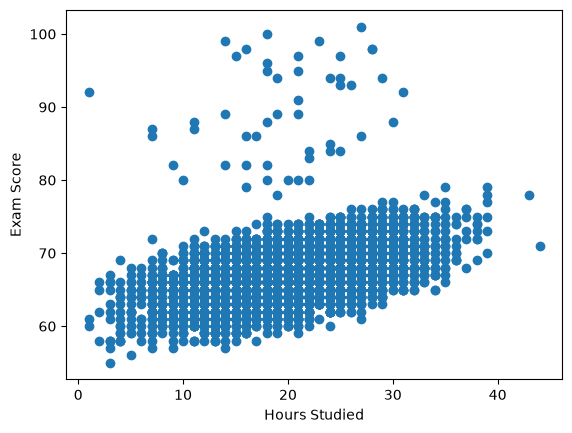

In [12]:
plt.scatter(studied, exam)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.show

The graph shows a positive relationship between hours studied and exam scores. Students who study more generally tend to achieve higher scores.

<function matplotlib.pyplot.show(close=None, block=None)>

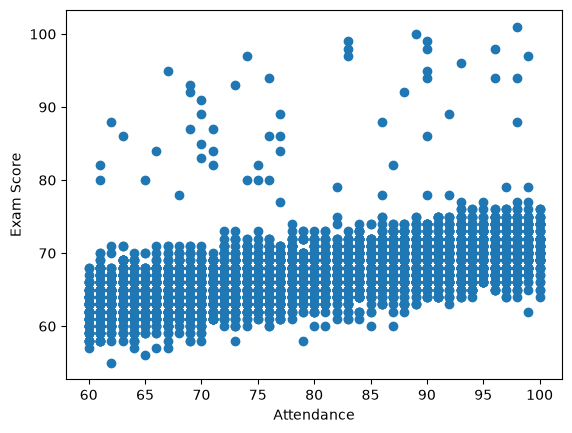

In [13]:
plt.scatter(attendance, exam)
plt.xlabel("Attendance")
plt.ylabel("Exam Score")
plt.show

The graph shows a positive relationship between attendance and exam scores. Attendance appears to be one of the more useful numerical features for predicting exam performance.

<function matplotlib.pyplot.show(close=None, block=None)>

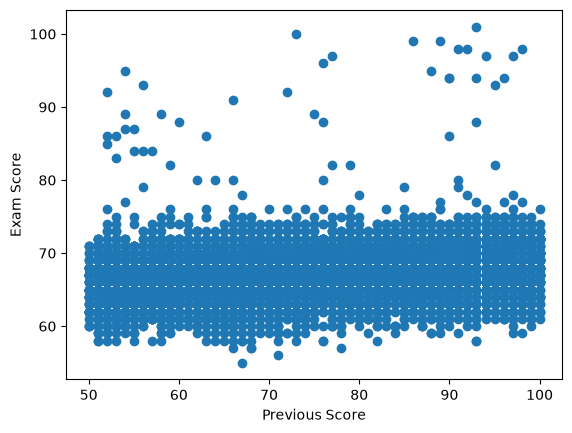

In [14]:
plt.scatter(previous, exam)
plt.xlabel("Previous Score")
plt.ylabel("Exam Score")
plt.show

The graph shows a small positive relationship between previous scores and exam scores. The pattern is weaker than the relationships seen for attendance and hours studied.

<function matplotlib.pyplot.show(close=None, block=None)>

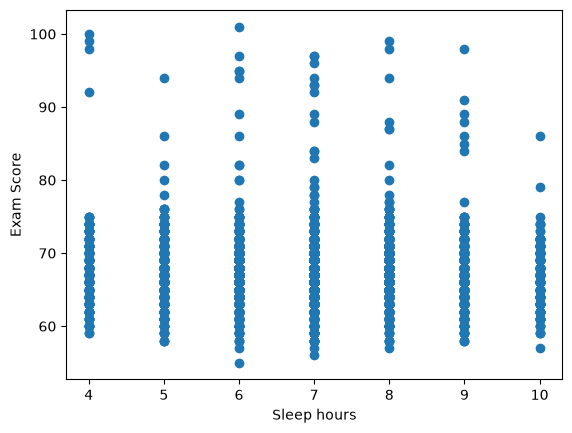

In [15]:
plt.scatter(sleep, exam)
plt.xlabel("Sleep hours")
plt.ylabel("Exam Score")
plt.show

The graph does not show a clear upward or downward pattern. Students with different amounts of sleep achieve a range of exam scores.

<function matplotlib.pyplot.show(close=None, block=None)>

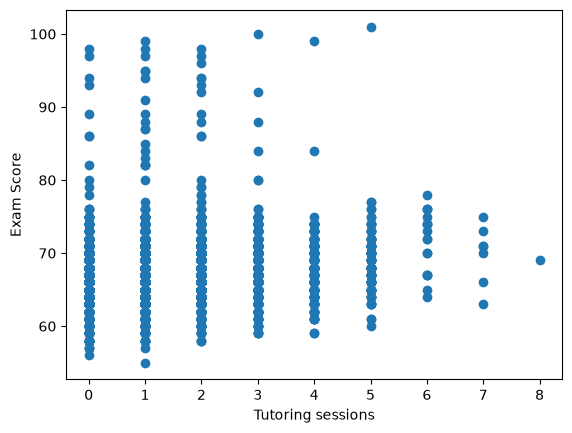

In [16]:
plt.scatter(tutor, exam)
plt.xlabel("Tutoring sessions")
plt.ylabel("Exam Score")
plt.show

The graph appears to show higher scores among some students with fewer tutoring sessions. However, this does not mean tutoring reduces performance, as students who need more support may already be struggling.

<function matplotlib.pyplot.show(close=None, block=None)>

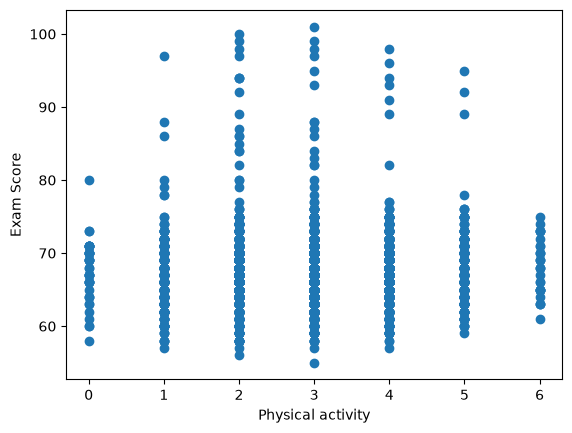

In [17]:
plt.scatter(activity, exam)
plt.xlabel("Physical activity")
plt.ylabel("Exam Score")
plt.show

Students reporting around 2–4 hours of physical activity appear to achieve higher scores in the graph. However, the number of students in each group may affect this pattern.

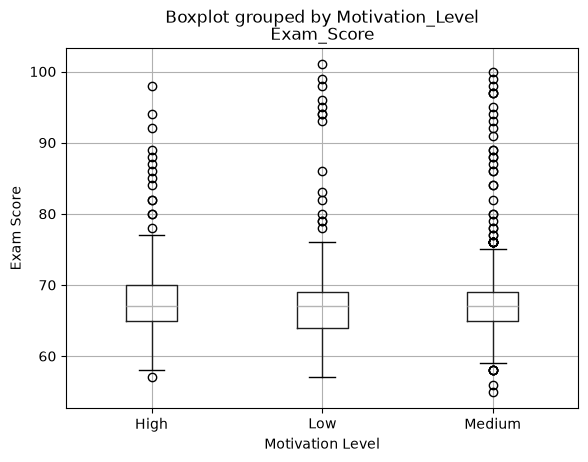

In [18]:
performance.boxplot(column="Exam_Score", by="Motivation_Level")
plt.xlabel("Motivation Level")
plt.ylabel("Exam Score")
plt.show()

The boxplot does not show a clear difference in exam scores between motivation levels. Motivation alone may not be a strong predictor, although it could still be useful alongside other features.

## 5. Check Correlations

Correlation measures the direction and strength of a linear relationship between numerical variables. Values closer to 1 indicate a positive relationship, while values closer to -1 indicate a negative relationship. Values near 0 indicate little linear relationship.

Correlation does not prove causation and a weak correlation does not necessarily mean a feature is useless for prediction.

In [19]:
correlations = performance.corr(numeric_only=True)

correlations['Exam_Score'].sort_values(ascending=False)

Exam_Score           1.000000
Attendance           0.580259
Hours_Studied        0.445104
Previous_Scores      0.174283
Tutoring_Sessions    0.156829
Physical_Activity    0.025148
Sleep_Hours         -0.017171
Name: Exam_Score, dtype: float64

### Initial Findings

- Attendance has the strongest positive correlation with Exam_Score among the numerical features examined.
- Hours_Studied also has a moderate positive correlation.
- Previous_Scores and Tutoring_Sessions have weaker positive correlations.
- Physical_Activity and Sleep_Hours have correlations close to zero.

These results suggest that attendance and hours studied may be useful predictors. However the other features will not automatically be removed, as their usefulness can be assessed when the machine learning models are tested.

## 6. Prepare the Data for Machine Learning

The aim is to predict Exam_Score using the other features in the dataset. The target variable is separated from the input features before training a machine learning model.

In [20]:
X = performance.drop('Exam_Score', axis=1)
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = performance['Exam_Score']

## 7. Split the Dataset

The dataset is split into training and testing sets. The training set is used to train the model, while the testing set is used to evaluate its predictions on unseen data.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 8. Train the Linear Regression Model

A Linear Regression model is created and trained using the training data. The model learns the relationship between the input features and exam scores so it can make predictions on the testing data.

In [22]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## 9. Make Predictions

After training the Linear Regression model, it is used to make predictions on the testing data. These predictions estimate the exam scores based on the input features.

In [23]:
predictions = model.predict(X_test)

print(predictions[:10])

[73.9727794  66.0035957  70.47205615 71.96451369 67.46034699 69.50296822
 72.26958042 66.23256449 68.84715288 67.94607836]


## 10. Evaluate the Model

The model is evaluated using Mean Absolute Error (MAE) and the R² score.

MAE measures the average difference between the actual exam scores and the predicted scores. A lower MAE means the predictions are closer to the actual scores.

The R² score measures how well the model explains the variation in exam scores. A score closer to 1 indicates a better fit.

In [24]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Absolute Error: 0.48728723427430964
R2 Score: 0.7314386522127073


## 11. Compare Actual and Predicted Scores

The actual exam scores are compared with the scores predicted by the Linear Regression model. This helps show how close the predictions are to the real exam results.

In [25]:
results = pd.DataFrame({
    'Actual Score': y_test,
    'Predicted Score': predictions
})

print(results.head(10))

      Actual Score  Predicted Score
2814            74        73.972779
4421            66        66.003596
4282            70        70.472056
1246            72        71.964514
4699            67        67.460347
235             69        69.502968
1679            72        72.269580
300             66        66.232564
5600            69        68.847153
5444            68        67.946078


## 12. Selected Features Model

Attendance and Hours_Studied were selected because they showed the strongest correlations with Exam_Score.

This model uses only these two features to predict exam scores. The aim is to compare its performance with the baseline model, which uses all available input features.

In [26]:
X_selected = performance[['Attendance', 'Hours_Studied']]
y_selected = performance['Exam_Score']

## 13. Split the Selected Features Dataset

The selected features are split into training and testing sets. The same 80% training and 20% testing split is used to evaluate the model on unseen data.

In [27]:
X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(
    X_selected, y_selected, test_size=0.2, random_state=42
)

## 14. Train the Selected Features Model

A second Linear Regression model is created and trained using only Attendance and Hours_Studied. This allows the model to learn the relationship between these two features and exam scores.

In [28]:
selected_model = LinearRegression()

selected_model.fit(X_train_selected, y_train_selected)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## 15. Make Predictions Using Selected Features

The trained model is used to predict exam scores using the testing data containing only Attendance and Hours_Studied.

In [29]:
selected_predictions = selected_model.predict(X_test_selected)

print(selected_predictions[:10])

[73.63041863 65.98932501 69.90038358 70.59958258 65.58978272 69.2168076
 69.52271351 65.19961424 63.62019272 67.93704279]


## 16. Evaluate the Selected Features Model

The selected-features model is evaluated using MAE and the R² score. These results are used to measure how accurately the model predicts exam scores using only the two selected features.

In [30]:
selected_mae = mean_absolute_error(y_test_selected, selected_predictions)
selected_r2 = r2_score(y_test_selected, selected_predictions)

print("Selected Model MAE:", selected_mae)
print("Selected Model R2:", selected_r2)

Selected Model MAE: 1.5299165703545727
Selected Model R2: 0.5483922658301799


## 17. Model Comparison

The baseline Linear Regression model uses all available input features, while the selected-features model uses only Attendance and Hours_Studied.

Their MAE and R² scores are compared to see which model produces more accurate predictions.

In [31]:
model_comparison = pd.DataFrame({
    'Model': ['Baseline Model', 'Selected Features Model'],
    'MAE': [mae, selected_mae],
    'R2 Score': [r2, selected_r2]
})

print(model_comparison)

                     Model       MAE  R2 Score
0           Baseline Model  0.487287  0.731439
1  Selected Features Model  1.529917  0.548392


## 18. Conclusion

The aim of this project was to explore factors that may be related to student exam performance and investigate whether machine learning could be used to predict exam scores.

The analysis showed that Attendance and Hours_Studied had the strongest correlations with Exam_Score in the dataset.

Two Linear Regression models were trained and evaluated. The baseline model, which used all available input features, achieved an MAE of approximately 0.49 and an R² score of 0.73. The selected-features model, which used only Attendance and Hours_Studied, achieved an MAE of approximately 1.53 and an R² score of 0.55.

The baseline model produced better predictions, suggesting that using additional features helped improve its performance. However, correlation does not prove that a particular factor causes higher exam scores.

Further work could involve testing other machine learning models, such as Decision Tree and Random Forest, and comparing their results with the Linear Regression models.